# Original group notebook (archived as-is). Data paths point to the team's private Google Drive; see the repository README to run the refactored code.

# We have a README file to explain all our main files.

# Project Overview: Weighted Hybrid Recommendation System

This project implements a **weighted hybrid recommendation system** that combines multiple models at different stages to improve recommendation accuracy and diversity.

## Workflow

### 1. **SVD Initial Recommendation (500 items)**
- **Method**: Collaborative Filtering using **Singular Value Decomposition (SVD)**.
- **Output**: Generate the top **500 candidate games** for each user.

### 2. **KNN & Content-Based Fusion (50% / 50%)**
- **KNN (50%)**:  
  - Uses user-based collaborative filtering with **K-nearest neighbors**.
  - Measures similarity based on historical gameplay patterns.
- **Content-Based (50%)**:
  - Combines **TF-IDF** and **BERT embeddings** for content similarity.
  - **TF-IDF (50%)**: Vectorizes game descriptions, tags, and genres.
  - **BERT (50%)**: Generates semantic embeddings from combined textual features.

### 3. **Final Weighted Score**
- For each candidate game:
  - Final score = **0.5 × KNN score + 0.5 × Content-Based score**.
  - Content-Based score = **0.5 × TF-IDF score + 0.5 × BERT score**.

### 4. **Top-N Selection**
- Rank all candidates by the final weighted score.
- Select the **Top 10** games per user.


# **CF - KNN**
generate 500 recommendations for our test users.

In [ ]:
# Baseline colleberative filtering - knn method.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

!pip install scikit-surprise
!pip install seaborn
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 3.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl size=2469542 sha256=edbe2f2fb54945af986afd1652e9b9338f5bba0a25eff4b5f246810782c7fd54
  Stored in directory: /root/.cache/pip/wheels/2a/8f/6e/7e2899163e2d85d8266daab4aa1cdabec7a6c56f83c015b5af
Successfully built scikit-surprise
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 64.2 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following 

    app_id  is_recommended  hours   user_id  \
0  1196590             1.0   19.0   5935019   
1   435150             1.0  199.9   6334645   
2   275850             1.0   13.6   6484333   
3   105600             1.0  911.8  10383001   
4  1794680             1.0   77.3  11659871   

                                  genre  rating  
0                                Action       4  
1                Adventure,RPG,Strategy       5  
2                      Action,Adventure       3  
3            Action,Adventure,Indie,RPG       5  
4  Action,Casual,Indie,RPG,Early Access       5  
unique games count: 3654
unique user count: 8225


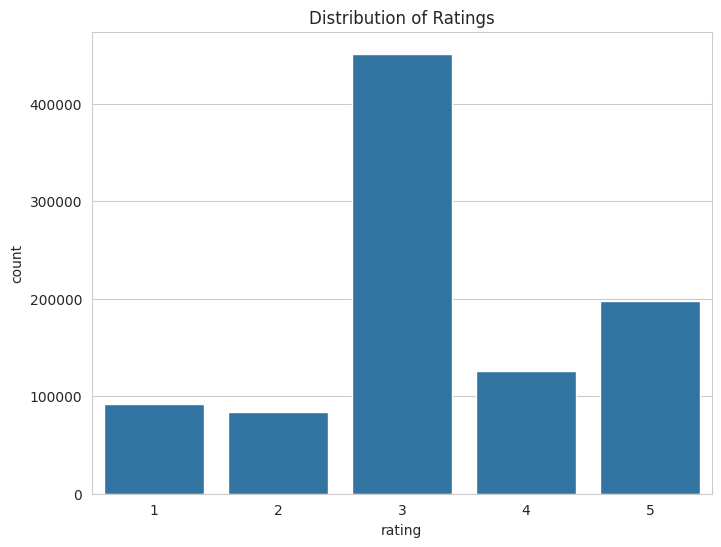

In [ ]:
from tqdm import tqdm
import pandas as pd
# tqdm.pandas()
# filtered_df['rating'] = filtered_df.progress_apply(assign_rating, axis=1)
# filtered_df.to_csv("/content/drive/My Drive/9727group/filtered_games_with_rating.csv", index=False)

csv_path = "/content/drive/My Drive/9727-group/filtered_games_with_rating.csv"
user_dataset = pd.read_csv(csv_path)
user_dataset['user_id'] = user_dataset['user_id'].astype(str).str.strip()
user_dataset['app_id'] = user_dataset['app_id'].astype(str).str.strip()
print(user_dataset.head())

unique_game_count = user_dataset['app_id'].nunique()
print("unique games count:", unique_game_count)
unique_user_count = user_dataset['user_id'].nunique()
print("unique user count:", unique_user_count)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize=(8,6))
sns.countplot(x='rating', data=user_dataset)
plt.title('Distribution of Ratings')
plt.show()

In [ ]:
from surprise import SVD
from surprise import Dataset, Reader
from sklearn.model_selection import train_test_split
import random
import pandas as pd
from tqdm import tqdm
tqdm.pandas()  # Enable progress bar for pandas apply() calls
RANDOM_STATE = 42
random.seed(RANDOM_STATE)

def assign_rating(row):
    if row['is_recommended'] and row['hours'] >= 25:
        return 5
    elif row['is_recommended'] and row['hours'] >= 10:
        return 4
    elif row['is_recommended']:
        return 3
    elif row['hours'] >= 5:
        return 2
    else:
        return 1

# Load sports dataset and assign ratings
# sport_dataset = pd.read_csv(sport_csv_path)
# sport_dataset['rating'] = sport_dataset.progress_apply(assign_rating, axis=1)
sport_csv_path = "/content/drive/My Drive/9727-group/user_sport.csv"
sport_dataset = pd.read_csv(sport_csv_path, encoding='ISO-8859-1')  # You can also try cp1252 / gbk if needed
sport_dataset['rating'] = sport_dataset.progress_apply(assign_rating, axis=1)
print(sport_dataset.head())

# Load FPS dataset and assign ratings
fps_csv_path = "/content/drive/My Drive/9727-group/user_call_of_duty.csv"
fps_dataset = pd.read_csv(fps_csv_path,  encoding='ISO-8859-1')
fps_dataset['rating'] = fps_dataset.progress_apply(assign_rating, axis=1)
print(fps_dataset.head())

# Ensure all IDs are strings for consistent matching
sport_dataset['user_id'] = sport_dataset['user_id'].astype(str)
sport_dataset['app_id'] = sport_dataset['app_id'].astype(str)
fps_dataset['user_id'] = fps_dataset['user_id'].astype(str)
fps_dataset['app_id'] = fps_dataset['app_id'].astype(str)
user_dataset['user_id'] = user_dataset['user_id'].astype(str)
user_dataset['app_id'] = user_dataset['app_id'].astype(str)

# Keep only relevant columns for the two real-user datasets
sport_data_filtered = sport_dataset[['user_id', 'app_id', 'rating']].copy()
fps_data_filtered = fps_dataset[['user_id', 'app_id', 'rating']].copy()

print(sport_data_filtered.head())
print(fps_data_filtered.head())

train_rows = []
test_rows = []

# Split each user's data into train/test parts so all users appear in both sets
for uid, group in user_dataset.groupby('user_id'):
      train_part, test_part = train_test_split(group, test_size=0.2, random_state=RANDOM_STATE)
      train_rows.append(train_part)
      test_rows.append(test_part)

pre_train_df = pd.concat(train_rows)
test_df = pd.concat(test_rows)

# Merge the main dataset with the two additional datasets
train_df = pd.concat([pre_train_df, sport_data_filtered, fps_data_filtered], ignore_index=True)

unique_test_games = test_df['app_id'].nunique()

reader = Reader(rating_scale=(1,5))
train_data = Dataset.load_from_df(train_df[['user_id', 'app_id', 'rating']], reader)
trainset = train_data.build_full_trainset()

testset = list(test_df[['user_id', 'app_id', 'rating']].itertuples(index=False, name=None))

from surprise import SVD
from surprise.model_selection import GridSearchCV
param_grid = {
    'n_factors': [100],
    'reg_all': [0.02]
}

# Run grid search to find best parameters based on RMSE
gs = GridSearchCV(SVD, param_grid, measures=['rmse'], cv=3)
gs.fit(train_data)

# Print the best RMSE score and corresponding parameters
print("Best RMSE score attained: ", gs.best_score['rmse'])
print("Best parameters: ", gs.best_params['rmse'])

# Train the best model on the full training set
best_algo = gs.best_estimator['rmse']
best_algo.fit(trainset)

# Evaluate on the test set
predictions = best_algo.test(testset)

for pred in predictions[:5]:
    print(pred)

from surprise import accuracy
# Compute RMSE on the test set
accuracy.rmse(predictions)


100%|██████████| 18/18 [00:00<00:00, 10465.41it/s]


    app_id  is_recommended       hours   user_id  \
0   960170               1  137.693657  22222222   
1   207140               1    9.420437  22222222   
2   681280               0   95.964967  22222222   
3  1506830               1  113.220339  22222222   
4   212480               1  139.873221  22222222   

                               genre  \
0               Action,Casual,Sports   
1  Action,Casual,Indie,Racing,Sports   
2               Action,Racing,Sports   
3                  Simulation,Sports   
4                      Racing,Sports   

                                      About the game  \
0  DJMAX RESPECT V delivers an unrivaled rhythm g...   
1  In a city filled with superheroes, getting to ...   
2  From the developers of Action Henk , Descender...   
3  Powered by Football?, EA SPORTS? FIFA 22 bring...   
4  Sonic and the All-Stars cast line up on the st...   

                                                Tags  \
0  Rhythm,Casual,Action,Music,Sports,Great Soundt... 

100%|██████████| 24/24 [00:00<00:00, 13780.05it/s]


    app_id  is_recommended      hours   user_id             genre  \
0   311210               1  48.511753  11111111  Action,Adventure   
1  1238880               1  79.786204  11111111            Action   
2  1938090               1  72.481927  11111111            Action   
3   202970               1   5.701436  11111111            Action   
4    42700               1  82.550724  11111111            Action   

                                      About the game  \
0  Call of Duty?: Black Ops III Zombies Chronicle...   
1  Strategy. Speed. Story. These are the core pil...   
2  Existing Modern Warfare? II Digital Standard E...   
3  Pushing the boundaries of what fans have come ...   
4  The biggest first-person action series of all ...   

                                                Tags  \
0  Multiplayer,FPS,Zombies,Shooter,Action,First-P...   
1  Action,Multiplayer,Singleplayer,Shooter,FPS,Wa...   
2  FPS,Action,Multiplayer,Shooter,Military,First-...   
3  Action,Multiplayer,FP

1.0061349957528516

In [ ]:
import random

# All users and games (external/raw IDs)
all_user_raw_ids = [trainset.to_raw_uid(uid) for uid in trainset.all_users()]
all_item_raw_ids = [trainset.to_raw_iid(iid) for iid in trainset.all_items()]

import pandas as pd

top_500_records = []

for uid in all_user_raw_ids:
    inner_uid = trainset.to_inner_uid(uid)
    interacted_inner_items = set(j for (j, _) in trainset.ur[inner_uid])
    interacted_raw_items = set(trainset.to_raw_iid(iid) for iid in interacted_inner_items)

    unseen_items = [iid for iid in all_item_raw_ids if iid not in interacted_raw_items]
    user_anti_testset = [(uid, iid, 0) for iid in unseen_items]

    predictions = best_algo.test(user_anti_testset)
    top_n = sorted(predictions, key=lambda x: x.est, reverse=True)[:500]

    for pred in top_n:
        top_500_records.append({
            'user_id': pred.uid,
            'app_id': pred.iid,
            'predicted_rating': pred.est
        })

# Save to CSV
top_500_df = pd.DataFrame(top_500_records)
top_500_df.to_csv('/content/drive/My Drive/9727-group/top500_predictions_for_sport_fps_users_new.csv', index=False)
print("Top 500 recommendations for each user have been saved to top500_predictions_for_sport_fps_users_new.csv")

Top 500 recommendations for each user have been saved to top500_predictions_for_sport_fps_users_new.csv


In [ ]:
import pandas as pd

# Read the generated top500 file
df = pd.read_csv('/content/drive/My Drive/9727-group/top500_predictions_for_sport_fps_users_new.csv')

# 1. Count the number of unique users
unique_user_count = df['user_id'].nunique()
print(f"Total number of unique users: {unique_user_count}")

# 2. Count how many recommendations each user received
user_counts = df['user_id'].value_counts()

# 3. Print the top 50 users and their recommendation counts
print("Top 50 users by number of recommendations:")
print(user_counts.head(50))

display(df)

Total number of unique users: 2
Top 50 users by number of recommendations:
user_id
11111111    500
22222222    500
Name: count, dtype: int64


,user_id,app_id,predicted_rating
0,11111111,1454400,5.000000
1,11111111,550,5.000000
2,11111111,673950,5.000000
3,11111111,637650,5.000000
4,11111111,223470,5.000000
...,...,...,...
995,22222222,1042550,4.308024
996,22222222,17480,4.307093
997,22222222,233450,4.306864
998,22222222,8930,4.305914


# **CF - KNN**
Use the 500 recommandations for two user from CF-SVD, then re-rank these 500 games for the two real users using CF-KNN.

In [ ]:
import pandas as pd
user_dataset = pd.read_csv("/content/drive/My Drive/9727-group/filtered_games.csv")
display(user_dataset)
user_dataset['user_id'] = user_dataset['user_id'].astype(str).str.strip()
user_dataset['app_id'] = user_dataset['app_id'].astype(str).str.strip()

unique_game_count = user_dataset['app_id'].nunique()
print("unique games count:", unique_game_count)
unique_user_count = user_dataset['user_id'].nunique()
print("unique users count:", unique_user_count)

,app_id,is_recommended,hours,user_id,genre
0,1196590,1.0,19.0,5935019,Action
1,435150,1.0,199.9,6334645,"Adventure,RPG,Strategy"
2,275850,1.0,13.6,6484333,"Action,Adventure"
3,105600,1.0,911.8,10383001,"Action,Adventure,Indie,RPG"
4,1794680,1.0,77.3,11659871,"Action,Casual,Indie,RPG,Early Access"
...,...,...,...,...,...
950350,253430,0.0,1.0,2444255,"Violent,Action,Adventure,Indie"
950351,897450,1.0,6.0,8857084,"Action,Adventure,Casual,Indie"
950352,1818450,1.0,1.0,13261742,"Action,Adventure,Massively Multiplayer,RPG"
950353,362960,1.0,35.0,7858713,"Adventure,RPG"


unique games count: 3654
unique users count: 8225


In [ ]:
import pandas as pd
# Add two real users to the original dataset.
# Load the user_sport_csv
sport_csv_path = "/content/drive/My Drive/9727-group/user_sport.csv"
sport_dataset = pd.read_csv(sport_csv_path, encoding='ISO-8859-1')

fps_csv_path = "/content/drive/My Drive/9727-group/user_call_of_duty.csv"
fps_dataset = pd.read_csv(fps_csv_path, encoding='ISO-8859-1')

# changae and equal the datatype
sport_dataset['user_id'] = sport_dataset['user_id'].astype(str)
sport_dataset['app_id'] = sport_dataset['app_id'].astype(str)
fps_dataset['user_id'] = fps_dataset['user_id'].astype(str)
fps_dataset['app_id'] = fps_dataset['app_id'].astype(str)
user_dataset['user_id'] = user_dataset['user_id'].astype(str)
user_dataset['app_id'] = user_dataset['app_id'].astype(str)

# Keep the needed.
sport_data_filtered = sport_dataset[['user_id', 'app_id', 'is_recommended']].copy()
fps_data_filtered = fps_dataset[['user_id', 'app_id', 'is_recommended']].copy()
user_data_filtered = user_dataset[['user_id', 'app_id', 'is_recommended']].copy()

# form the training set.
train_df = pd.concat([user_data_filtered, sport_data_filtered, fps_data_filtered], ignore_index=True)
display(train_df)

,user_id,app_id,is_recommended
0,5935019,1196590,1.0
1,6334645,435150,1.0
2,6484333,275850,1.0
3,10383001,105600,1.0
4,11659871,1794680,1.0
...,...,...,...
950392,11111111,284160,1.0
950393,11111111,609490,1.0
950394,11111111,253430,1.0
950395,11111111,793350,1.0


In [ ]:
from surprise import KNNBasic
from surprise import Dataset, Reader
from surprise import SVD
from surprise import Dataset, Reader
from sklearn.model_selection import train_test_split
import random
import pandas as pd
from surprise.model_selection import train_test_split

reader = Reader(rating_scale=(0, 1))
data = Dataset.load_from_df(train_df[['user_id', 'app_id', 'is_recommended']], reader)
# Use all filtered_games csv data as training set.
trainset = data.build_full_trainset()

In [ ]:
# method 1: KNN.
from surprise import KNNBasic
# item-based CF
sim_options = {
    'name': 'cosine',
    'user_based': False     # Item-based
}
algo = KNNBasic()
algo.fit(trainset)

Computing the msd similarity matrix...
Done computing similarity matrix.


In [ ]:
import pandas as pd
# load the results from CF-SVD method.
cb_df = pd.read_csv("/content/drive/My Drive/9727-group/top500_predictions_for_sport_fps_users_new.csv")
cb_df['user_id'] = cb_df['user_id'].astype(str).str.strip()
cb_df['app_id'] = cb_df['app_id'].astype(str).str.strip()
display(cb_df)
unique_user_count = cb_df['user_id'].nunique()
print("Unique user in cb_df:", unique_user_count)
unique_game_count = cb_df['app_id'].nunique()
print("Unique game in cb_df:", unique_game_count)

,user_id,app_id,predicted_rating
0,11111111,1454400,5.000000
1,11111111,550,5.000000
2,11111111,673950,5.000000
3,11111111,637650,5.000000
4,11111111,223470,5.000000
...,...,...,...
995,22222222,1042550,4.308024
996,22222222,17480,4.307093
997,22222222,233450,4.306864
998,22222222,8930,4.305914


Unique user in cb_df: 2
Unique game in cb_df: 661


In [ ]:
# Create the anti_testset in Surprise style.
cb_testset = [(str(row.user_id), str(row.app_id), 0) for _, row in cb_df.iterrows()]
predictions = algo.test(cb_testset)

In [ ]:
# give each 500 game score.
def get_top_n_recommendations_with_scores(predictions, n=500):
    top_n = {}
    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

top_n = get_top_n_recommendations_with_scores(predictions, n=500)

for uid, user_ratings in list(top_n.items())[:5]:
    print(f"Top 10 recommendations for user {uid}:")
    for iid, est in user_ratings:
        print(f"    Game ID: {iid} | Predicted Score: {est:.3f}")

Top 10 recommendations for user 11111111:
    Game ID: 550 | Predicted Score: 1.000
    Game ID: 105600 | Predicted Score: 1.000
    Game ID: 2058190 | Predicted Score: 1.000
    Game ID: 1009850 | Predicted Score: 1.000
    Game ID: 222880 | Predicted Score: 1.000
    Game ID: 250760 | Predicted Score: 1.000
    Game ID: 648100 | Predicted Score: 1.000
    Game ID: 22380 | Predicted Score: 1.000
    Game ID: 1044620 | Predicted Score: 1.000
    Game ID: 927380 | Predicted Score: 1.000
    Game ID: 620 | Predicted Score: 1.000
    Game ID: 4580 | Predicted Score: 1.000
    Game ID: 570940 | Predicted Score: 1.000
    Game ID: 1718570 | Predicted Score: 1.000
    Game ID: 1257290 | Predicted Score: 1.000
    Game ID: 280680 | Predicted Score: 1.000
    Game ID: 34330 | Predicted Score: 1.000
    Game ID: 1593500 | Predicted Score: 1.000
    Game ID: 1324130 | Predicted Score: 1.000
    Game ID: 1559390 | Predicted Score: 1.000
    Game ID: 466300 | Predicted Score: 1.000
    Game ID: 32

In [ ]:
recommendation_records = [
    (uid, iid, est) for uid, user_ratings in top_n.items() for (iid, est) in user_ratings
]

# create the dataframe.
recommendation_df = pd.DataFrame(recommendation_records, columns=['user_id', 'app_id', 'score'])

# create the csv as the result of cf-knn model.
recommendation_df.to_csv('/content/drive/My Drive/9727-group/cf_knn_top500_with_scores_with_real_users.csv', index=False)

In [ ]:
# check the result.
top500 = pd.read_csv("/content/drive/My Drive/9727-group/cf_knn_top500_with_scores_with_real_users.csv")
unique_game_count = top500['app_id'].nunique()
print("unique games count:", unique_game_count)
unique_user_count = top500['user_id'].nunique()
print("filtered_games_with_rating  unique user count:", unique_user_count)
display(top500)

unique games count: 661
filtered_games_with_rating  unique user count: 2


,user_id,app_id,score
0,11111111,550,1.000
1,11111111,105600,1.000
2,11111111,2058190,1.000
3,11111111,1009850,1.000
4,11111111,222880,1.000
...,...,...,...
995,22222222,214950,0.675
996,22222222,1063730,0.675
997,22222222,534380,0.625
998,22222222,644930,0.625


# **CB -tf-idf & bert**
Use the 500 recommandations for two user from CF-SVD, and generate score for these 500 games.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import MultiLabelBinarizer, MinMaxScaler

In [ ]:
# load data
df = pd.read_csv('/content/drive/My Drive/9727-group/merged_filtered_games.csv')
game_df = df.drop_duplicates(subset='app_id').reset_index(drop=True)

In [ ]:
def concat_features(row):
    return ' '.join([
        str(row.get('About the game', '')),
        str(row.get('Tags', '')),
        str(row.get('genre', '')),
        str(row.get('Categories', '')),
        str(row.get('Developers', '')),
        str(row.get('Publishers', ''))
    ])

game_df['combined_features'] = game_df.apply(concat_features, axis=1)


In [ ]:
# TF-IDF vector
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
tfidf_matrix = vectorizer.fit_transform(game_df['About the game'].fillna(''))
app_id_to_index = {aid: i for i, aid in enumerate(game_df['app_id'])}


In [ ]:
# BERT embedding
model = SentenceTransformer('all-MiniLM-L6-v2')
bert_embeddings = model.encode(game_df['combined_features'].tolist(), show_progress_bar=True)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/115 [00:00<?, ?it/s]

In [ ]:
# genre one-hot
def split_and_strip(s):
    if pd.isna(s): return []
    return [x.strip() for x in str(s).replace(';', ',').split(',') if x.strip()]

game_df['genres_list'] = game_df['genre'].apply(split_and_strip)
mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(game_df['genres_list'])

# price normalize
game_df['Price'] = pd.to_numeric(game_df['Price'], errors='coerce').fillna(0)
scaler = MinMaxScaler()
game_df['Price_norm'] = scaler.fit_transform(game_df[['Price']])


In [ ]:
# ----------- user profile -----------
def get_user_profile(user_id):
    played = df[(df['user_id'] == user_id)]
    if played.empty:
        return None

    valid_indices, weights = [], []
    for _, row in played.iterrows():
        app_id = row['app_id']
        if app_id in app_id_to_index:
            valid_indices.append(app_id_to_index[app_id])
            weights.append(row['hours'])

    if not valid_indices:
        return None

    weights = np.array(weights)
    tfidf_vector = np.asarray(tfidf_matrix[valid_indices].mean(axis=0)).flatten()
    content_vec = np.average(bert_embeddings[valid_indices], axis=0, weights=weights)
    genre_vec = np.average(genre_matrix[valid_indices], axis=0, weights=weights)
    price_pref = game_df.iloc[valid_indices]['Price_norm'].mean()

    return tfidf_vector, content_vec, genre_vec, price_pref


In [ ]:
# generate score
candidates_df = pd.read_csv('/content/drive/My Drive/9727-group/top500_predictions.csv')
result_rows = []

for user_id in candidates_df['user_id'].unique():
    profile = get_user_profile(user_id)
    if profile is None:
        print(f"User {user_id} has no positive history.")
        continue

    tfidf_vector, user_content, user_genre, user_price = profile
    tfidf_vector_dense = np.asarray(tfidf_vector).reshape(1, -1)

    user_candidates = candidates_df[candidates_df['user_id'] == user_id]
    app_ids = user_candidates['app_id'].tolist()

    indices = [app_id_to_index[aid] for aid in app_ids if aid in app_id_to_index]
    if not indices:
        continue

    tfidf_scores = cosine_similarity(tfidf_vector_dense, tfidf_matrix[indices]).flatten()
    content_scores = np.dot(bert_embeddings[indices], user_content)
    genre_scores = genre_matrix[indices] @ user_genre
    price_scores = 1 - np.abs(game_df.iloc[indices]['Price_norm'].values - user_price)

    # weight score
    final_scores = (
        0.5 * tfidf_scores +
        0.45 * content_scores +
        0.15 * genre_scores +
        0.15 * price_scores
    )

    for idx, score in zip(indices, final_scores):
        result_rows.append({
            'user_id': user_id,
            'app_id': game_df.iloc[idx]['app_id'],
            'score': score
        })

# return new CSV
output_df = pd.DataFrame(result_rows)
output_df.to_csv('/content/drive/My Drive/9727-group/cb_scored_recommendations.csv', index=False)
print("cb_scored_recommendations.csv")

cb_scored_recommendations.csv


# **Combine two csv and get final result**

In [ ]:
import pandas as pd

# Load CB and CF results
cb_df = pd.read_csv("/content/drive/My Drive/9727-group/cb_scored_recommendations_for_new_users.csv")
cf_df = pd.read_csv("/content/drive/My Drive/9727-group/cf_knn_top500_with_scores_with_real_users.csv")

cb_df = cb_df.rename(columns={'score': 'cb_score'})
cf_df = cf_df.rename(columns={'score': 'cf_score'})

merged = pd.merge(cb_df, cf_df, on=['user_id', 'app_id'], how='inner')

# Weighted score
merged['score'] = 0.5 * merged['cb_score'] + 0.5 * merged['cf_score']

# Select top 10 games
top10_df = (
    merged.sort_values(by=['user_id', 'score'], ascending=[True, False])
    .groupby('user_id')
    .head(10)
    .reset_index(drop=True)
)


top10_df = top10_df[['user_id', 'app_id', 'score']]

top10_df.to_csv('/content/drive/My Drive/9727-group/real_user_colab_top10_weighted_recommendations.csv', index=False)

In [ ]:
weighted_final_results = pd.read_csv("/content/drive/My Drive/9727-group/real_user_colab_top10_weighted_recommendations.csv")
display(weighted_final_results)

,user_id,app_id,score
0,11111111,200710,0.790618
1,11111111,222880,0.789544
2,11111111,274190,0.777509
3,11111111,220240,0.773242
4,11111111,13570,0.772022
5,11111111,244450,0.769507
6,11111111,219990,0.764640
7,11111111,1718570,0.764578
8,11111111,550,0.760262
9,11111111,620,0.757263
